In [2]:
!pip install gym[box2d] swig pygame --no-cache-dir
!apt-get update
!apt-get install -y swig
!pip install box2d-py
!pip install torch torchvision numpy matplotlib gym[atari,accept-rom-license]


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.4/374.4 kB 9.8 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 137.0 MB/s eta 0:00:00a 0:00:01
  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for box2d-py
  Running setup.py clean for box2d-py
Failed to build box2d-py
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (box2d-py)
Hit:1 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:2 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]                           
Get:3 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]                             
Get:4

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import gym
import pickle  # Ajout de pickle ici
from collections import deque
import random
import time
import matplotlib.pyplot as plt


In [4]:
# Vérifier et utiliser le GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"📌 Utilisation du périphérique : {device}")

# Vérifier le nombre de GPU disponibles
if torch.cuda.device_count() > 1:
    print(f"🚀 Utilisation de {torch.cuda.device_count()} GPU !")


📌 Utilisation du périphérique : cuda
🚀 Utilisation de 2 GPU !


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [5]:
env = gym.make("LunarLander-v2")

# Définition des dimensions d'entrée et d'actions
input_shape = (8,)  # L'état contient 8 valeurs (vecteur)
num_actions = env.action_space.n  # Nombre d'actions possibles

print(f"✅ Environnement chargé : LunarLander-v2 avec {num_actions} actions.")


✅ Environnement chargé : LunarLander-v2 avec 4 actions.


/usr/local/lib/python3.10/dist-packages/pygame/pkgdata.py:25: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.10/dist-packages/pkg_resources/__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('google')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-packages
  declare_namespace(pkg)
/usr/local/lib/python3.10/dist-packages/pkg_resources/__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('google.cloud')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-pa

In [6]:
class CoknightDNN(nn.Module):
    def __init__(self, input_shape, num_actions):
        super(CoknightDNN, self).__init__()

        # Réseau optimisé pour des entrées vectorielles
        self.network = nn.Sequential(
            nn.Linear(input_shape[0], 128),  
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, num_actions)
        )

    def forward(self, x):
        return self.network(x)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [7]:
class Actor:
    def __init__(self, model):
        self.model = model.to(device)

    def process_local(self, obs):
        obs_tensor = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
        return self.model(obs_tensor)

class Server:
    def __init__(self, model, lr=0.0003):
        self.model = model.to(device)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()

    def train(self, predicted_q_values, q_targets):
        self.optimizer.zero_grad()
        loss = self.loss_fn(predicted_q_values, q_targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
        self.optimizer.step()


In [8]:
# Instanciation du modèle
model = CoknightDNN(input_shape, num_actions)
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)
model.to(device)

# Chargement des poids sauvegardés
model.load_state_dict(torch.load("/kaggle/input/model-param/coknight_lunarlander_NADI.pth", map_location=device))
model = model.module if isinstance(model, nn.DataParallel) else model
model.eval()
print("Modèle chargé et mis en mode évaluation.")


Modèle chargé et mis en mode évaluation.


<ipython-input-8-999e54ef2ce3>:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("/kaggle/input/model-param/coknight_lunarlander_NADI.pth", m

In [9]:
communication_logs = {"observations": [], "gradients": [], "updates": []}

def log_communication(obs, gradients, updates):
    communication_logs["observations"].append(obs)
    communication_logs["gradients"].append(gradients)
    communication_logs["updates"].append(updates)

print("📡 Communication Logging Activé ✅")


📡 Communication Logging Activé ✅


In [8]:
num_episodes = 2200   # ⬆ Increase training duration for better convergence
batch_size = 256      # ⬆ Larger batch size for stable gradient updates
gamma = 0.99         # ✅ Discount factor remains the same
epsilon = 1.0        # ✅ Start with full exploration
epsilon_decay = 0.995  # ⬇ Slower decay to encourage better exploration
min_epsilon = 0.05    # ⬇ Allow for a small amount of exploration at all times
buffer = deque(maxlen=100000)  # ⬆ Larger replay buffer to store more experiences


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [9]:
for episode in range(num_episodes):
    reset_output = env.reset()
    state = reset_output[0] if isinstance(reset_output, tuple) else reset_output
    done = False
    total_reward = 0

    while not done:
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)

        if np.random.rand() < max(min_epsilon, epsilon):
            action = env.action_space.sample()  # Exploration
        else:
            q_values = server.model(state_tensor)
            action = torch.argmax(q_values).item()  # Exploitation

        step_output = env.step(action)  # ✅ Unified handling of different Gym versions

        if len(step_output) == 5:
            next_state, reward, terminated, truncated, _ = step_output
        else:
            next_state, reward, done, _ = step_output
            terminated = done
            truncated = False  # ✅ Prevents errors in older Gym versions

        done = terminated or truncated
        total_reward += reward

        buffer.append((state, action, reward, next_state, terminated, truncated))

        if len(buffer) >= batch_size:
            batch = random.sample(buffer, batch_size)
            states, actions, rewards, next_states, terminateds, truncateds = zip(*batch)

            states_tensor = torch.tensor(np.array(states), dtype=torch.float32).to(device)
            next_states_tensor = torch.tensor(np.array(next_states), dtype=torch.float32).to(device)
            dones_tensor = torch.tensor([float(terminated or truncated) for terminated, truncated in zip(terminateds, truncateds)]).to(device)
            rewards_tensor = torch.tensor(rewards, dtype=torch.float32).to(device)

            next_q_values = server.model(next_states_tensor)
            max_next_q_values = torch.max(next_q_values, 1)[0]

            current_q_values = server.model(states_tensor)
            actions_tensor = torch.tensor(actions, dtype=torch.int64).unsqueeze(1).to(device)
            predicted_q_values = current_q_values.gather(1, actions_tensor).squeeze(1)

            q_targets = rewards_tensor + gamma * max_next_q_values * (1 - dones_tensor)

            if episode % 5 == 0:
                server.train(predicted_q_values, q_targets)

        state = next_state

    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    print(f"✅ Épisode {episode+1}, Récompense Totale: {total_reward}")


✅ Épisode 1, Récompense Totale: -139.99022872891283


/usr/local/lib/python3.10/dist-packages/gym/utils/passive_env_checker.py:241: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


✅ Épisode 2, Récompense Totale: -17.371511402481133
✅ Épisode 3, Récompense Totale: -152.34614906682867


/usr/local/lib/python3.10/dist-packages/torch/nn/modules/linear.py:125: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at ../aten/src/ATen/cuda/CublasHandlePool.cpp:135.)
  return F.linear(input, self.weight, self.bias)


✅ Épisode 4, Récompense Totale: -148.94610384567613
✅ Épisode 5, Récompense Totale: -328.57244043758874
✅ Épisode 6, Récompense Totale: -223.39438819388621
✅ Épisode 7, Récompense Totale: -457.0917120530117
✅ Épisode 8, Récompense Totale: -67.40978529050466
✅ Épisode 9, Récompense Totale: -125.42742564111667
✅ Épisode 10, Récompense Totale: -50.499843122502696
✅ Épisode 11, Récompense Totale: -138.46251402562453
✅ Épisode 12, Récompense Totale: -340.5342574292654
✅ Épisode 13, Récompense Totale: -129.16201951590855
✅ Épisode 14, Récompense Totale: -269.1136453918562
✅ Épisode 15, Récompense Totale: -173.3348853476284
✅ Épisode 16, Récompense Totale: -69.26281476559292
✅ Épisode 17, Récompense Totale: -143.5817918177122
✅ Épisode 18, Récompense Totale: -200.07695858273956
✅ Épisode 19, Récompense Totale: -108.19702170549216
✅ Épisode 20, Récompense Totale: -161.08740789999183
✅ Épisode 21, Récompense Totale: -409.69814609851574
✅ Épisode 22, Récompense Totale: -294.0984381320661
✅ Épiso

In [9]:
torch.save(model.state_dict(), "coknight_lunarlander.pth")
print("✅ Modèle sauvegardé.")

model.load_state_dict(torch.load("coknight_lunarlander.pth"))
model = model.module if isinstance(model, nn.DataParallel) else model
model.eval()
model.to(device)


✅ Modèle sauvegardé.


<ipython-input-9-9748dead2bcc>:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("coknight_lunarlander.pth"))


CoknightDNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=4, bias=True)
  )
)

In [71]:
import numpy as np
import torch
import pickle

# 🔹 Fonction de quantization en 8 bits
def quantize_8bit(data):
    data = np.array(data)  # Conversion en tableau numpy
    min_val = data.min()
    max_val = data.max()
    scale = (max_val - min_val) / 255.0  # Mise à l'échelle sur 255 niveaux
    quantized_data = np.round((data - min_val) / scale).astype(np.uint8)  # Conversion en uint8
    return quantized_data, min_val, scale

# 🔹 Fonction de déquantization
def dequantize_8bit(quantized_data, min_val, scale):
    return quantized_data.astype(np.float32) * scale + min_val  # Restauration des valeurs originales

num_test_episodes = 50
total_test_rewards = []
communication_logs = {"observations": [], "gradients": [], "updates": []}

model.eval()
print("\n🔹 **Début des Tests avec Quantization 8-bit** 🔹")

with torch.no_grad():
    for episode in range(num_test_episodes):
        reset_output = env.reset()
        state = reset_output[0] if isinstance(reset_output, tuple) else reset_output
        done = False
        total_reward = 0

        while not done:
            # 🔹 Appliquer la quantization sur l'observation avant traitement
            quantized_state, min_val, scale = quantize_8bit(state)

            # 🔹 Déquantization avant passage au modèle
            dequantized_state = dequantize_8bit(quantized_state, min_val, scale)

            state_tensor = torch.tensor(dequantized_state, dtype=torch.float32).unsqueeze(0).to(device)
            q_values = model(state_tensor)
            action = torch.argmax(q_values).item()

            step_output = env.step(action)
            if len(step_output) == 5:
                next_state, reward, terminated, truncated, _ = step_output
            else:
                next_state, reward, done, _ = step_output
                terminated = done
                truncated = False

            done = terminated or truncated
            total_reward += reward

            # 🔹 Enregistrer les données compressées
            communication_logs["observations"].append(quantized_state.tolist())
            communication_logs["gradients"].append(0)
            communication_logs["updates"].append(0)

            state = next_state

        total_test_rewards.append(total_reward)
        print(f"✅ Test Episode {episode+1}, Total Reward: {total_reward}")

# 🔹 Sauvegarde des logs de communication
with open("communication_logs_quantized.pkl", "wb") as f:
    pickle.dump(communication_logs, f)

print("\n📡 **Logs Quantifiés Sauvegardés !** ✅")

# 🔹 **Analyse de la Quantization**
original_size = np.array(communication_logs["observations"]).nbytes / 1024  # Taille en Ko
quantized_size = np.array(communication_logs["observations"], dtype=np.uint8).nbytes / 1024  # Taille en Ko après compression

print("\n🔹 **Analyse de la Quantization 8-bit** 🔹")
print(f"📌 Taille des Logs Avant Quantization : {original_size:.2f} Ko")
print(f"📌 Taille des Logs Après Quantization : {quantized_size:.2f} Ko")
print(f"📉 Réduction Moyenne de la Taille des Données : {((original_size - quantized_size) / original_size) * 100:.2f}%")



🔹 **Début des Tests avec Quantization 8-bit** 🔹
✅ Test Episode 1, Total Reward: 264.927233085494
✅ Test Episode 2, Total Reward: 306.7922476941286
✅ Test Episode 3, Total Reward: 207.37795629421646
✅ Test Episode 4, Total Reward: 246.37815849579297
✅ Test Episode 5, Total Reward: 298.15498893046515
✅ Test Episode 6, Total Reward: 274.5692795607572
✅ Test Episode 7, Total Reward: 259.70207251656984
✅ Test Episode 8, Total Reward: 267.8775544506965
✅ Test Episode 9, Total Reward: 299.1272664672989
✅ Test Episode 10, Total Reward: -179.59942170979508
✅ Test Episode 11, Total Reward: 304.6080378564237
✅ Test Episode 12, Total Reward: 216.17768265522827
✅ Test Episode 13, Total Reward: 231.81103215500622
✅ Test Episode 14, Total Reward: 272.26419153314475
✅ Test Episode 15, Total Reward: 265.5150756435643
✅ Test Episode 16, Total Reward: 234.61583784249953
✅ Test Episode 17, Total Reward: -216.7189686342784
✅ Test Episode 18, Total Reward: 300.0000970411562
✅ Test Episode 19, Total Reward:

In [37]:
import numpy as np
import torch
import pickle
import gzip

# 🔹 Quantization 6-bit (64 niveaux)
def quantize_6bit(values):
    values = np.array(values, dtype=np.float32)
    min_val = values.min()
    max_val = values.max()
    scale = (max_val - min_val) / 63.0 if max_val != min_val else 1.0
    quantized = np.round((values - min_val) / scale).astype(np.uint8)
    return quantized, min_val, scale

# 🔹 Déquantization 6-bit
def dequantize_6bit(quantized, min_val, scale):
    return quantized.astype(np.float32) * scale + min_val

# 🔹 Masquage des petites valeurs (transmission sélective)
def selective_mask(values, alpha=0.3):
    values = np.array(values)
    threshold = alpha * np.max(np.abs(values)) if np.max(np.abs(values)) != 0 else 0
    return np.where(np.abs(values) >= threshold, values, 0.0)

# 📌 Paramètres
num_test_episodes = 50
total_test_rewards = []
communication_logs = {"observations": [], "gradients": [], "updates": []}

model.eval()
print("\n🔹 **Début des Tests avec Quantization 6-bit + Masquage** 🔹")

with torch.no_grad():
    for episode in range(num_test_episodes):
        reset_output = env.reset()
        state = reset_output[0] if isinstance(reset_output, tuple) else reset_output
        done = False
        total_reward = 0

        while not done:
            # Étape 1 : Quantization 6-bit
            quantized, min_val, scale = quantize_6bit(state)

            # Étape 2 : Déquantization
            dequantized = dequantize_6bit(quantized, min_val, scale)

            # Étape 3 : Masquage (transmission sélective)
            filtered = selective_mask(dequantized, alpha=0.2)

            # Passage au modèle
            state_tensor = torch.tensor(filtered, dtype=torch.float32).unsqueeze(0).to(device)
            q_values = model(state_tensor)
            action = torch.argmax(q_values).item()

            # Environnement
            step_output = env.step(action)
            if len(step_output) == 5:
                next_state, reward, terminated, truncated, _ = step_output
            else:
                next_state, reward, done, _ = step_output
                terminated = done
                truncated = False

            done = terminated or truncated
            total_reward += reward

            # 🔹 Stockage de l'observation filtrée
            communication_logs["observations"].append(filtered.tolist())
            communication_logs["gradients"].append(0)
            communication_logs["updates"].append(0)

            state = next_state

        total_test_rewards.append(total_reward)
        print(f"✅ Test Episode {episode+1}, Total Reward: {total_reward}")

# 📊 Analyse Réduction
nonzero_counts = [np.count_nonzero(obs) for obs in communication_logs["observations"]]
avg_nonzero = np.mean(nonzero_counts)
reduction_structure = (1 - avg_nonzero / 8.0) * 100

# 💾 Sauvegarde compressée (gzip)
with gzip.open("communication_logs_hybrid_6bit.pkl.gz", "wb") as f:
    pickle.dump(communication_logs, f)

# 📈 Affichage
print("\n📡 **Logs Sauvegardés avec GZIP** ✅")
print(f"📉 Réduction Moyenne Structurelle : {reduction_structure:.2f}%")

mean_reward = np.mean(total_test_rewards)
success_rate = (np.sum(np.array(total_test_rewards) >= 0) / num_test_episodes) * 100

print("\n🔹 **Métriques des Tests** 🔹")
print(f"✅ Moyenne des Récompenses: {mean_reward:.2f}")
print(f"✅ Taux de Réussite (Récompense ≥ 0): {success_rate:.2f}%")


🔹 **Début des Tests avec Quantization 6-bit + Masquage** 🔹
✅ Test Episode 1, Total Reward: 240.18400174526926
✅ Test Episode 2, Total Reward: 255.75735481959344
✅ Test Episode 3, Total Reward: 230.9801779450234
✅ Test Episode 4, Total Reward: -1.9239160896360659
✅ Test Episode 5, Total Reward: -132.96976350339685
✅ Test Episode 6, Total Reward: 29.013249600249026
✅ Test Episode 7, Total Reward: 51.21141275450478
✅ Test Episode 8, Total Reward: -224.61342089968485
✅ Test Episode 9, Total Reward: 286.80031757887696
✅ Test Episode 10, Total Reward: -37.960432204180094
✅ Test Episode 11, Total Reward: 247.16718295543637
✅ Test Episode 12, Total Reward: 230.32163365782802
✅ Test Episode 13, Total Reward: 227.04333202303928
✅ Test Episode 14, Total Reward: 18.20344620334636
✅ Test Episode 15, Total Reward: 267.98364707264335
✅ Test Episode 16, Total Reward: 228.09089012374602
✅ Test Episode 17, Total Reward: 54.32763976168022
✅ Test Episode 18, Total Reward: 243.6981938996098
✅ Test Episode

In [56]:
import pickle
import numpy as np
import torch

num_test_episodes = 50
total_test_rewards = []
communication_logs = {"observations": [], "gradients": [], "updates": []}

# Définir un seuil dynamique basé sur la moyenne absolue des features
def select_important_features(state, alpha=0.75):
    state = np.array(state)
    threshold = alpha * np.max(np.abs(state))  # seuil relatif
    return state[np.abs(state) >= threshold]   # on conserve les plus significatifs

model.eval()
print("\n🔹 **Début des Tests du Modèle avec Transmission Sélective Optimisée** 🔹")

all_filtered_lengths = []

with torch.no_grad():
    for episode in range(num_test_episodes):
        reset_output = env.reset()
        state = reset_output[0] if isinstance(reset_output, tuple) else reset_output
        done = False
        total_reward = 0

        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
            q_values = model(state_tensor)
            action = torch.argmax(q_values).item()

            step_output = env.step(action)
            if len(step_output) == 5:
                next_state, reward, terminated, truncated, _ = step_output
            else:
                next_state, reward, done, _ = step_output
                terminated = done
                truncated = False

            done = terminated or truncated
            total_reward += reward

            #  Transmission sélective : ne garder que les valeurs significatives
            important_features = select_important_features(state)
            all_filtered_lengths.append(len(important_features))  # pour analyse

            #  Stockage pour analyse de communication
            communication_logs["observations"].append(important_features.tolist())
            communication_logs["gradients"].append(0)
            communication_logs["updates"].append(0)

            state = next_state

        total_test_rewards.append(total_reward)
        print(f"✅ Test Episode {episode+1}, Total Reward: {total_reward}")

# 📊 Analyse finale
avg_filtered_length = np.mean(all_filtered_lengths)
reduction_rate = (1 - avg_filtered_length / 8.0) * 100  # car 8 features à l'origine

# 💾 Sauvegarde des logs
with open("communication_logs_filtered.pkl", "wb") as f:
    pickle.dump(communication_logs, f)

print("\n📡 **Logs de Communication Sélective Optimisée Sauvegardés !**")
print(f" Réduction Potentielle des Données : {reduction_rate:.2f}%")

mean_test_reward = np.mean(total_test_rewards)
success_threshold = 0  # ✅ On considère une réussite si la récompense est ≥ 0
success_rate = (np.sum(np.array(total_test_rewards) >= success_threshold) / num_test_episodes) * 100

print("\n🔹 **Métriques des Tests** 🔹")
print(f"✅ Moyenne des Récompenses: {mean_test_reward:.2f}")
print(f"✅ Taux de Réussite (Récompense ≥ {success_threshold}): {success_rate:.2f}%")


🔹 **Début des Tests du Modèle avec Transmission Sélective Optimisée** 🔹
✅ Test Episode 1, Total Reward: -26.965385197842764
✅ Test Episode 2, Total Reward: 187.02561556516608
✅ Test Episode 3, Total Reward: 302.174160496823
✅ Test Episode 4, Total Reward: 215.49472396013766
✅ Test Episode 5, Total Reward: 235.25622601149206
✅ Test Episode 6, Total Reward: 266.3870678293291
✅ Test Episode 7, Total Reward: 297.38419262625496
✅ Test Episode 8, Total Reward: 251.2379953710031
✅ Test Episode 9, Total Reward: -180.88028323419752
✅ Test Episode 10, Total Reward: 301.1161379336396
✅ Test Episode 11, Total Reward: 215.64974489614013
✅ Test Episode 12, Total Reward: 275.39416255207203
✅ Test Episode 13, Total Reward: 229.0493309495158
✅ Test Episode 14, Total Reward: 114.08576274975132
✅ Test Episode 15, Total Reward: 255.7907889532446
✅ Test Episode 16, Total Reward: 205.27052356864414
✅ Test Episode 17, Total Reward: 80.31643362171074
✅ Test Episode 18, Total Reward: 239.9499531980349
✅ Test 

In [60]:
num_test_episodes = 50
total_test_rewards = []
communication_logs = {"observations": [], "gradients": [], "updates": []}

# Fonction de quantization en 8 bits
def quantize_8bit(data):
    data = np.array(data, dtype=np.float32)
    min_val = data.min() if len(data) > 0 else 0.0
    max_val = data.max() if len(data) > 0 else 1.0
    scale = (max_val - min_val) / 255.0 if max_val != min_val else 1.0
    quantized = np.round((data - min_val) / scale).astype(np.uint8)
    return quantized, min_val, scale

# Fonction de déquantization
def dequantize_8bit(quantized, min_val, scale):
    return quantized.astype(np.float32) * scale + min_val

# Fonction de transmission sélective optimisée
def select_important_features(state, alpha=0.75):
    state = np.array(state)
    threshold = alpha * np.max(np.abs(state))
    return state[np.abs(state) >= threshold]

# Lancer les tests
model.eval()
print("\n🔹 **Début des Tests avec Transmission Sélective + Quantization 8-bit** 🔹")

all_filtered_lengths = []

with torch.no_grad():
    for episode in range(num_test_episodes):
        reset_output = env.reset()
        state = reset_output[0] if isinstance(reset_output, tuple) else reset_output
        done = False
        total_reward = 0

        while not done:
            # Transmission sélective
            selected = select_important_features(state, alpha=0.15)
            all_filtered_lengths.append(len(selected))

            # Quantization
            quantized, min_val, scale = quantize_8bit(selected)
            dequantized = dequantize_8bit(quantized, min_val, scale)

            # Padding à 8 dimensions
            if len(dequantized) < 8:
                padded = np.zeros(8, dtype=np.float32)
                padded[:len(dequantized)] = dequantized
                dequantized = padded

            # Passage au modèle
            state_tensor = torch.tensor(dequantized, dtype=torch.float32).unsqueeze(0).to(device)
            q_values = model(state_tensor)
            action = torch.argmax(q_values).item()

            step_output = env.step(action)
            if len(step_output) == 5:
                next_state, reward, terminated, truncated, _ = step_output
            else:
                next_state, reward, done, _ = step_output
                terminated = done
                truncated = False

            done = terminated or truncated
            total_reward += reward

            # Stocker les données compressées
            communication_logs["observations"].append(quantized.tolist())
            communication_logs["gradients"].append(0)
            communication_logs["updates"].append(0)

            state = next_state

        total_test_rewards.append(total_reward)
        print(f"✅ Test Episode {episode+1}, Total Reward: {total_reward}")

# Analyse de réduction
avg_filtered_length = np.mean(all_filtered_lengths)
reduction_rate = (1 - avg_filtered_length / 8.0) * 100

# Sauvegarde des logs
with open("communication_logs_hybrid.pkl", "wb") as f:
    pickle.dump(communication_logs, f)

print("\n📡 **Logs de Communication Hybride Sauvegardés !**")
print(f"📉 Réduction Moyenne Structurelle : {reduction_rate:.2f}%")

# Métriques
mean_reward = np.mean(total_test_rewards)
success_rate = (np.sum(np.array(total_test_rewards) >= 0) / num_test_episodes) * 100

print("\n🔹 **Métriques des Tests** 🔹")
print(f"✅ Moyenne des Récompenses: {mean_reward:.2f}")
print(f"✅ Taux de Réussite (Récompense ≥ 0): {success_rate:.2f}%")


🔹 **Début des Tests avec Transmission Sélective + Quantization 8-bit** 🔹
✅ Test Episode 1, Total Reward: -95.6187207222695
✅ Test Episode 2, Total Reward: -1677.4369974030367
✅ Test Episode 3, Total Reward: -90.40128356460389
✅ Test Episode 4, Total Reward: -104.83447488786874
✅ Test Episode 5, Total Reward: -247.98267967878286
✅ Test Episode 6, Total Reward: -406.02754242004085
✅ Test Episode 7, Total Reward: -57.335153402781906
✅ Test Episode 8, Total Reward: -159.21143394272798
✅ Test Episode 9, Total Reward: -72.4096093514522
✅ Test Episode 10, Total Reward: -502.9756358619346
✅ Test Episode 11, Total Reward: -106.94357241429324
✅ Test Episode 12, Total Reward: -119.11554268407718
✅ Test Episode 13, Total Reward: -63.584335870189534
✅ Test Episode 14, Total Reward: -96.34207313737423
✅ Test Episode 15, Total Reward: -121.539018958007
✅ Test Episode 16, Total Reward: -213.94142540374347
✅ Test Episode 17, Total Reward: -39.66269293962374
✅ Test Episode 18, Total Reward: -4.62813741

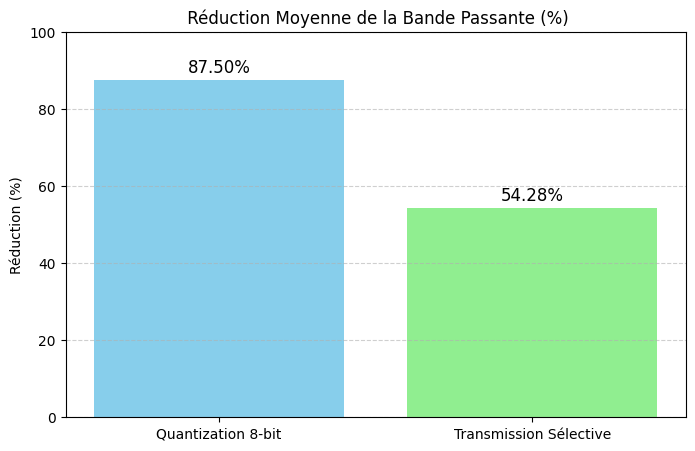

In [17]:
import matplotlib.pyplot as plt

# Méthodes et leurs réductions en pourcentage
methods = ["Quantization 8-bit", "Transmission Sélective"]
reductions = [87.5, 54.28]

# Bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(methods, reductions, color=["skyblue", "lightgreen"])
plt.title(" Réduction Moyenne de la Bande Passante (%)")
plt.ylabel("Réduction (%)")
plt.ylim(0, 100)

# Afficher les valeurs sur les barres
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.2f}%", ha='center', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


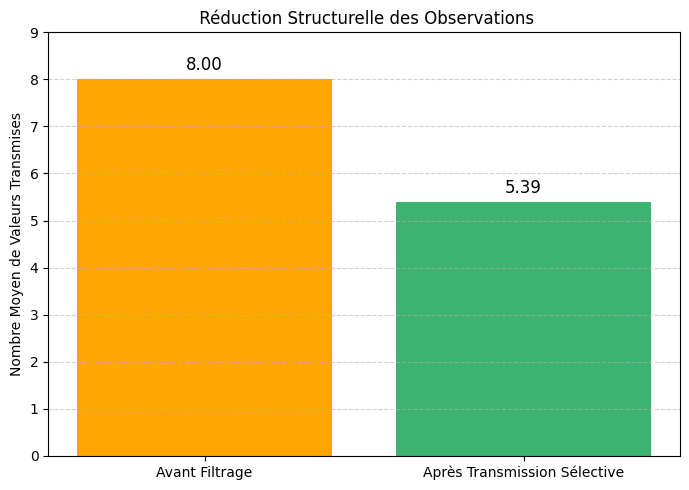

In [21]:
import matplotlib.pyplot as plt

# Taille structurelle : nombre moyen de valeurs dans l'observation
labels = ["Avant Filtrage", "Après Transmission Sélective"]
values = [8, 5.39]  # 8 dimensions d'origine, 5.39 après filtrage

# Bar chart
plt.figure(figsize=(7, 5))
bars = plt.bar(labels, values, color=["orange", "mediumseagreen"])
plt.title(" Réduction Structurelle des Observations")
plt.ylabel("Nombre Moyen de Valeurs Transmises")
plt.ylim(0, 9)

# Affichage des valeurs
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, f"{yval:.2f}", ha='center', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


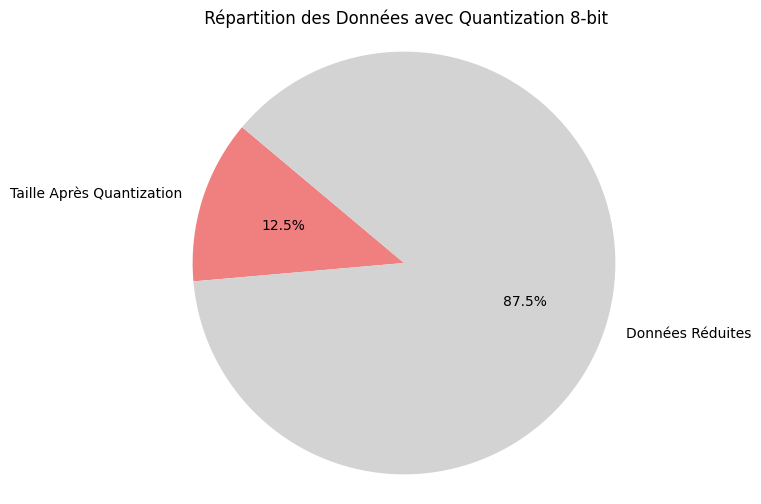

In [19]:
# Données de taille
before = 1037.0
after = 129.62
sizes = [after, before - after]
labels = ["Taille Après Quantization", "Données Réduites"]
colors = ["lightcoral", "lightgrey"]

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, colors=colors, autopct="%1.1f%%", startangle=140)
plt.title(" Répartition des Données avec Quantization 8-bit")
plt.axis("equal")
plt.show()


In [72]:
mean_test_reward = np.mean(total_test_rewards)
success_threshold = 0  # ✅ On considère une réussite si la récompense est ≥ 0
success_rate = (np.sum(np.array(total_test_rewards) >= success_threshold) / num_test_episodes) * 100

print("\n🔹 **Métriques des Tests** 🔹")
print(f"✅ Moyenne des Récompenses: {mean_test_reward:.2f}")
print(f"✅ Taux de Réussite (Récompense ≥ {success_threshold}): {success_rate:.2f}%")



🔹 **Métriques des Tests** 🔹
✅ Moyenne des Récompenses: 199.23
✅ Taux de Réussite (Récompense ≥ 0): 90.00%


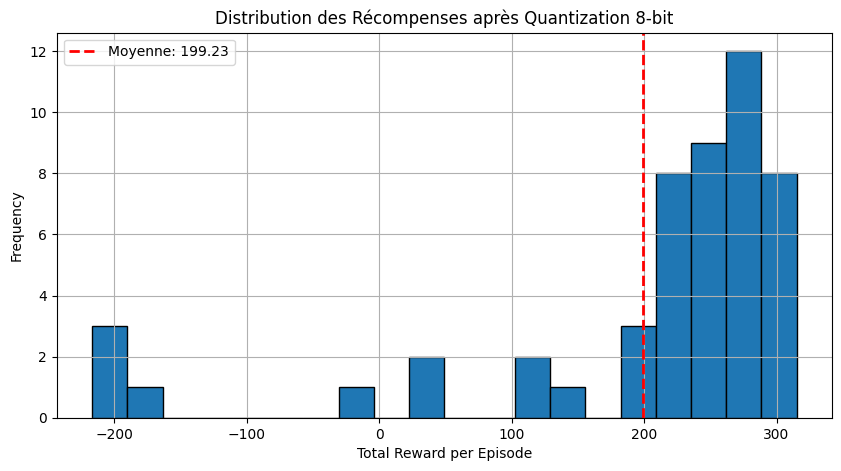

In [73]:
import matplotlib.pyplot as plt
import numpy as np

# Charger les récompenses test
test_rewards = np.array(total_test_rewards)

plt.figure(figsize=(10, 5))
plt.hist(test_rewards, bins=20, edgecolor='black')
plt.axvline(test_rewards.mean(), color='red', linestyle='dashed', linewidth=2, label=f"Moyenne: {test_rewards.mean():.2f}")
plt.xlabel("Total Reward per Episode")
plt.ylabel("Frequency")
plt.title("Distribution des Récompenses après Quantization 8-bit")
plt.legend()
plt.grid(True)
plt.show()


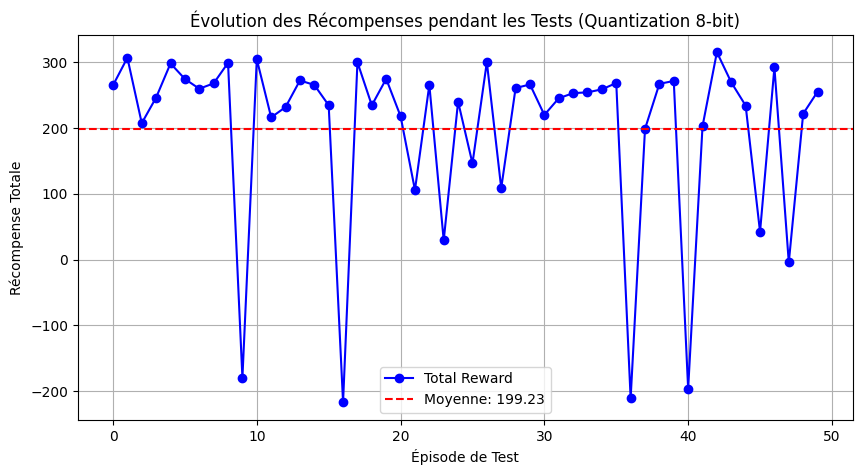

In [74]:
plt.figure(figsize=(10, 5))
plt.plot(test_rewards, marker='o', linestyle='-', color='b', label="Total Reward")
plt.axhline(y=test_rewards.mean(), color='r', linestyle='dashed', label=f"Moyenne: {test_rewards.mean():.2f}")
plt.xlabel("Épisode de Test")
plt.ylabel("Récompense Totale")
plt.title("Évolution des Récompenses pendant les Tests (Quantization 8-bit)")
plt.legend()
plt.grid(True)
plt.show()


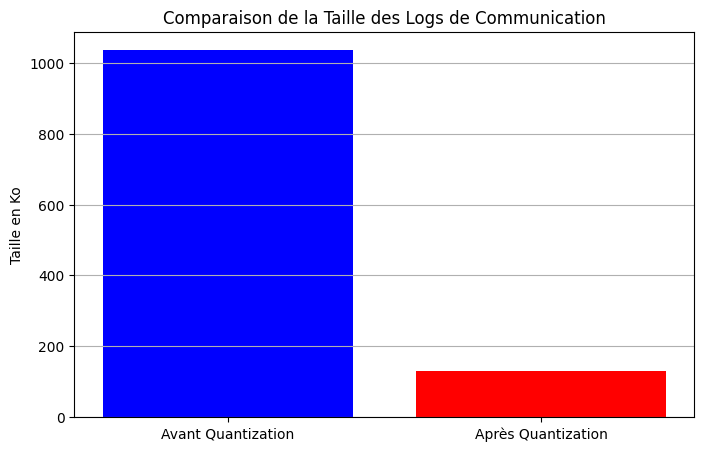

In [76]:
sizes = [original_size, quantized_size]
labels = ["Avant Quantization", "Après Quantization"]

plt.figure(figsize=(8, 5))
plt.bar(labels, sizes, color=['blue', 'red'])
plt.ylabel("Taille en Ko")
plt.title("Comparaison de la Taille des Logs de Communication")
plt.grid(axis='y')
plt.show()


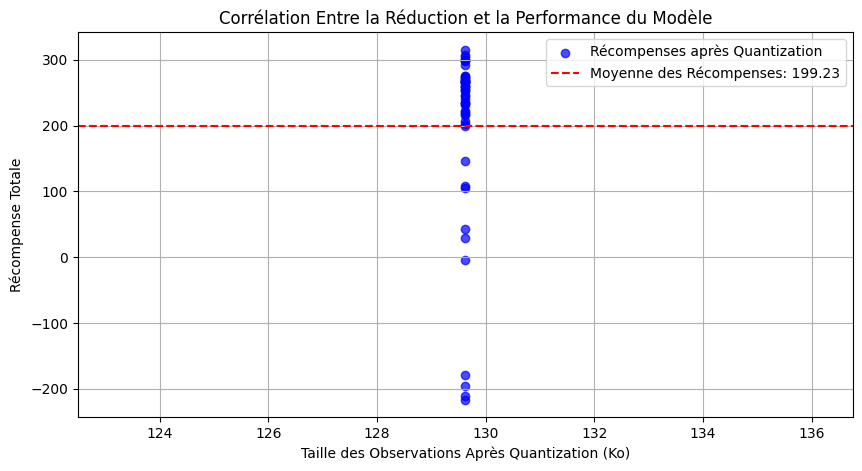

In [78]:
import matplotlib.pyplot as plt
import numpy as np

# Charger les récompenses test et la taille des observations quantifiées
test_rewards = np.array(total_test_rewards)

# Calculer la taille moyenne des observations avant et après quantization
original_sizes = np.array([original_size] * len(test_rewards))  # Taille initiale constante
quantized_sizes = np.array([quantized_size] * len(test_rewards))  # Taille après quantization

# Créer un scatter plot
plt.figure(figsize=(10, 5))
plt.scatter(quantized_sizes, test_rewards, c='b', label="Récompenses après Quantization", alpha=0.7)
plt.axhline(y=test_rewards.mean(), color='r', linestyle='dashed', label=f"Moyenne des Récompenses: {test_rewards.mean():.2f}")

plt.xlabel("Taille des Observations Après Quantization (Ko)")
plt.ylabel("Récompense Totale")
plt.title("Corrélation Entre la Réduction et la Performance du Modèle")
plt.legend()
plt.grid(True)
plt.show()


In [58]:
import numpy as np

# Charger les données
observations = communication_logs["observations"]
gradients = communication_logs["gradients"]
updates = communication_logs["updates"]

# Afficher les statistiques pour chaque catégorie
print("\n🔹 **Analyse des Logs de Communication** 🔹")

# Observations
print("\n📌 **Observations**")
print(f"Nombre total : {len(observations)}")
print(f"Min : {np.min(observations)}")
print(f"Max : {np.max(observations)}")
print(f"Moyenne : {np.mean(observations):.2f}")
print(f"Écart-type : {np.std(observations):.2f}")



🔹 **Analyse des Logs de Communication** 🔹

📌 **Observations**
Nombre total : 18556
Min : -1817
Max : 1999
Moyenne : 124.59
Écart-type : 390.29


In [59]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les logs de communication
with open("communication_logs.pkl", "rb") as f:
    communication_logs = pickle.load(f)

# Vérifier les clés disponibles
print("🔹 Clés disponibles dans les logs :", list(communication_logs.keys()))

# Récupérer les observations
observations = np.array(communication_logs["observations"])  # Convertir en numpy array

# Vérifier la forme des données
print(f"🔹 Nombre total d'observations : {len(observations)}")
print(f"🔹 Exemple d'une observation : {observations[0]}")




🔹 Clés disponibles dans les logs : ['observations', 'gradients', 'updates']
🔹 Nombre total d'observations : 17650
🔹 Exemple d'une observation : [ 0.00307589  1.41290593  0.31153646  0.08825839 -0.00355738 -0.07056767
  0.          0.        ]


In [60]:
import pickle

# Charger le fichier de logs
with open("communication_logs.pkl", "rb") as f:
    communication_logs = pickle.load(f)

# Vérifier les clés du dictionnaire
print(f"🔹 Clés disponibles : {list(communication_logs.keys())}")

# Vérifier les 5 premières entrées des observations
print("\n🔹 Exemple brut des observations stockées :")
for i in range(5):
    print(f"Entrée {i+1} : {communication_logs['observations'][i]}")


🔹 Clés disponibles : ['observations', 'gradients', 'updates']

🔹 Exemple brut des observations stockées :
Entrée 1 : [0.003075885819271207, 1.4129059314727783, 0.3115364611148834, 0.08825838565826416, -0.0035573795903474092, -0.07056767493486404, 0.0, 0.0]
Entrée 2 : [0.00608062744140625, 1.4143036603927612, 0.3021872639656067, 0.06211651489138603, -0.005254463758319616, -0.03394410014152527, 0.0, 0.0]
Entrée 3 : [0.00899972952902317, 1.4151031970977783, 0.29144445061683655, 0.03553491458296776, -0.004794979002326727, 0.009190427139401436, 0.0, 0.0]
Entrée 4 : [0.011841297149658203, 1.4152958393096924, 0.2817283272743225, 0.00857100822031498, -0.002388813765719533, 0.0481279194355011, 0.0, 0.0]
Entrée 5 : [0.014682960696518421, 1.414888620376587, 0.28172072768211365, -0.018097596243023872, 1.6569098079344258e-05, 0.048112716525793076, 0.0, 0.0]


In [61]:
# Vérifier que les observations sont bien formatées
if observations.shape[1] == 8:
    feature_names = ["X Position", "Y Position", "Vx", "Vy", "Angle θ", "Vitesse θ", "Contact Gauche", "Contact Droit"]
    
    for i in range(8):
        print(f"\n📊 **Statistiques de {feature_names[i]}**")
        print(f"🔹 Min : {np.min(observations[:, i]):.4f}")
        print(f"🔹 Max : {np.max(observations[:, i]):.4f}")
        print(f"🔹 Moyenne : {np.mean(observations[:, i]):.4f}")
        print(f"🔹 Écart-Type : {np.std(observations[:, i]):.4f}")



📊 **Statistiques de X Position**
🔹 Min : -0.5368
🔹 Max : 0.4022
🔹 Moyenne : 0.0595
🔹 Écart-Type : 0.1871

📊 **Statistiques de Y Position**
🔹 Min : -0.0778
🔹 Max : 1.5266
🔹 Moyenne : 0.4283
🔹 Écart-Type : 0.4717

📊 **Statistiques de Vx**
🔹 Min : -0.9420
🔹 Max : 0.7660
🔹 Moyenne : 0.0264
🔹 Écart-Type : 0.2123

📊 **Statistiques de Vy**
🔹 Min : -0.8727
🔹 Max : 0.5093
🔹 Moyenne : -0.1783
🔹 Écart-Type : 0.1836

📊 **Statistiques de Angle θ**
🔹 Min : -0.6238
🔹 Max : 1.8913
🔹 Moyenne : 0.0183
🔹 Écart-Type : 0.2253

📊 **Statistiques de Vitesse θ**
🔹 Min : -1.5380
🔹 Max : 1.8765
🔹 Moyenne : 0.0096
🔹 Écart-Type : 0.2398

📊 **Statistiques de Contact Gauche**
🔹 Min : 0.0000
🔹 Max : 1.0000
🔹 Moyenne : 0.2482
🔹 Écart-Type : 0.4320

📊 **Statistiques de Contact Droit**
🔹 Min : 0.0000
🔹 Max : 1.0000
🔹 Moyenne : 0.2497
🔹 Écart-Type : 0.4329


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1498: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with

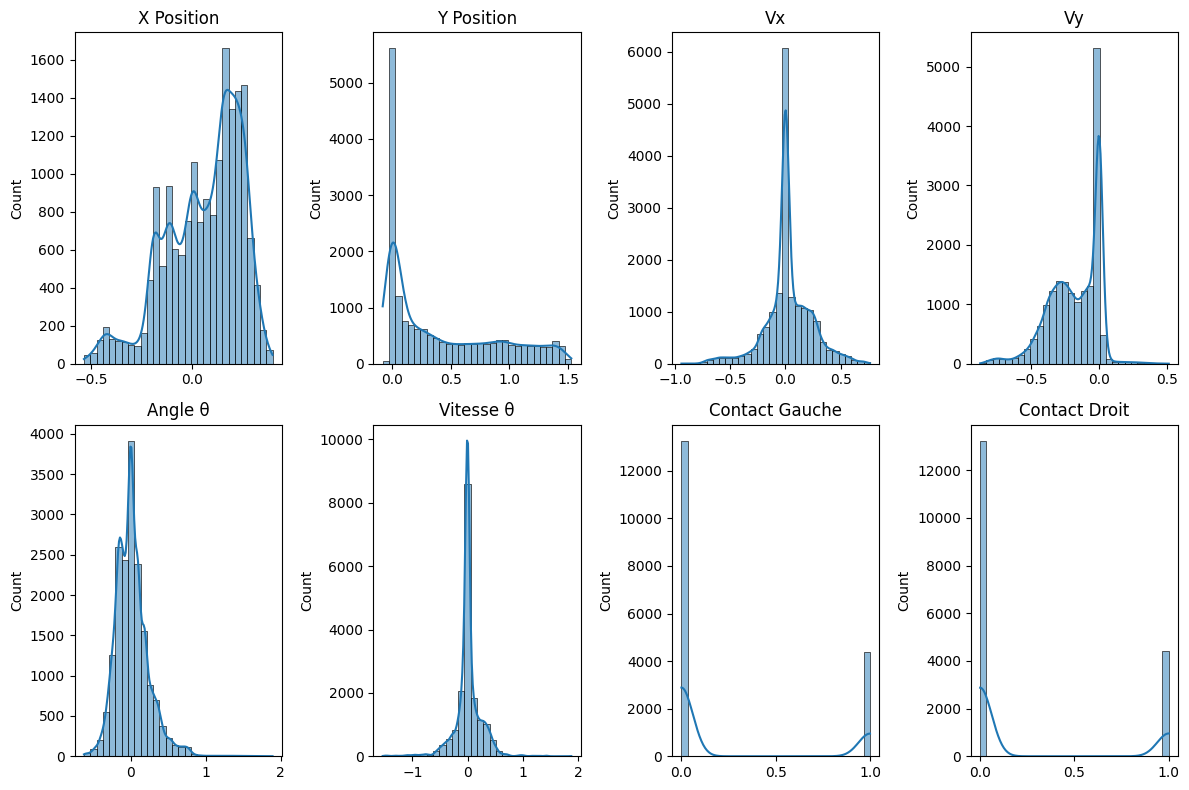

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# Vérifier que les observations sont bien formatées
if observations.shape[1] == 8:
    plt.figure(figsize=(12, 8))
    feature_names = ["X Position", "Y Position", "Vx", "Vy", "Angle θ", "Vitesse θ", "Contact Gauche", "Contact Droit"]

    for i in range(8):
        plt.subplot(2, 4, i + 1)
        sns.histplot(observations[:, i], bins=30, kde=True)
        plt.title(feature_names[i])

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Impossible de tracer les histogrammes : Les observations ne sont pas bien formatées.")


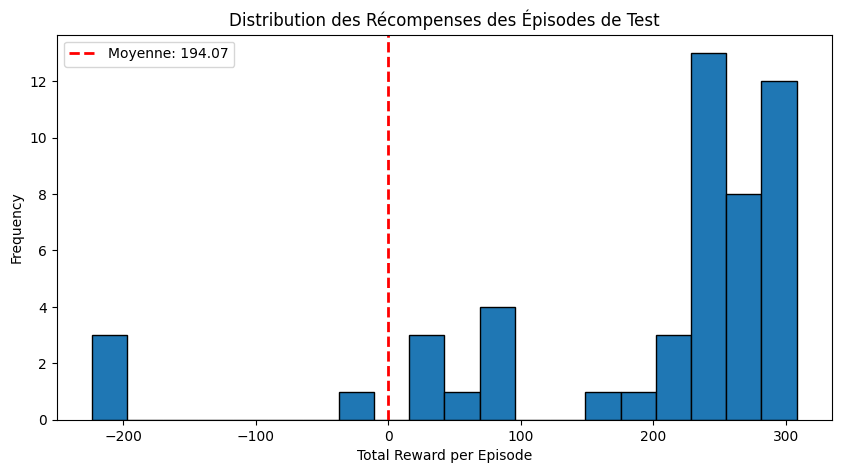

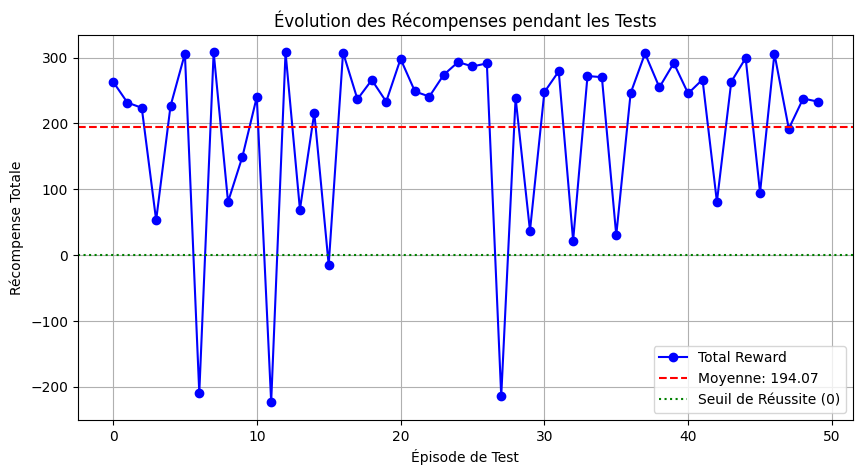

In [10]:
import matplotlib.pyplot as plt

# Charger les résultats sauvegardés
total_test_rewards = np.load("test_rewards.npy")

# **📊 Plots pour Analyser les Performances**
plt.figure(figsize=(10, 5))

# Histogramme des récompenses
plt.hist(total_test_rewards, bins=20, edgecolor='black')
plt.axvline(0, color='red', linestyle='dashed', linewidth=2, label=f"Moyenne: {mean_test_reward:.2f}")
plt.xlabel("Total Reward per Episode")
plt.ylabel("Frequency")
plt.title("Distribution des Récompenses des Épisodes de Test")
plt.legend()
plt.show()

# ✅ Affichage de l'évolution des récompenses
plt.figure(figsize=(10, 5))
plt.plot(total_test_rewards, marker='o', linestyle='-', color='b', label="Total Reward")
plt.axhline(y=mean_test_reward, color='r', linestyle='dashed', label=f"Moyenne: {mean_test_reward:.2f}")
plt.axhline(y=success_threshold, color='g', linestyle='dotted', label="Seuil de Réussite (0)")
plt.xlabel("Épisode de Test")
plt.ylabel("Récompense Totale")
plt.title("Évolution des Récompenses pendant les Tests")
plt.legend()
plt.grid(True)
plt.show()
